In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [13]:
df = pd.read_csv("../data/simulation_results2.csv")
df.head()

,sim,model_knowledge,w,perf
0,0,0.0,0.00,0.052734
1,0,0.0,0.01,-0.255859
2,0,0.0,0.02,-0.380859
3,0,0.0,0.03,-0.189453
4,0,0.0,0.04,-0.162109


In [17]:
df_plot = (
    df.groupby(["model_knowledge", "w"], as_index=False)["perf"]
      .mean()
      .assign(
          model_knowledge=lambda d: ((d["model_knowledge"] - 0.5) / 0.5).round(2),
          w=lambda d: d["w"].round(2)
      )
)
df_plot.head()

,model_knowledge,w,perf
0,-1.0,0.00,0.131973
1,-1.0,0.01,0.131387
2,-1.0,0.02,0.119355
3,-1.0,0.03,0.110605
4,-1.0,0.04,0.100527


In [18]:
matrix = df_plot.pivot(index="model_knowledge", columns="w", values="perf")
matrix.head()

w,0.00,0.01,0.02,0.03,0.04,0.05,0.06,0.07,0.08,0.09,...,0.91,0.92,0.93,0.94,0.95,0.96,0.97,0.98,0.99,1.00
model_knowledge,,,,,,,,,,,,,,,,,,,,,
-1.00,0.131973,0.131387,0.119355,0.110605,0.100527,0.078184,0.084824,0.079980,0.082988,0.072207,...,-0.516152,-0.494277,-0.485879,-0.507246,-0.516699,-0.519512,-0.516152,-0.513145,-0.507559,-0.500059
-0.98,0.139316,0.130371,0.113691,0.096270,0.109160,0.075059,0.076504,0.070176,0.078379,0.060059,...,-0.524551,-0.507324,-0.480957,-0.495254,-0.513887,-0.535840,-0.492715,-0.488652,-0.484434,-0.499590
-0.96,0.135684,0.133691,0.127246,0.111504,0.084004,0.089902,0.096465,0.094121,0.082871,0.072637,...,-0.514395,-0.500176,-0.494863,-0.493262,-0.508965,-0.490020,-0.506504,-0.487988,-0.504863,-0.475957
-0.94,0.124004,0.127480,0.117207,0.124199,0.103730,0.099668,0.085879,0.089082,0.087441,0.056895,...,-0.502520,-0.507402,-0.510176,-0.491699,-0.507090,-0.519629,-0.513145,-0.503184,-0.485527,-0.486660
-0.92,0.134004,0.108770,0.124941,0.130020,0.081855,0.090410,0.104668,0.072832,0.079121,0.068301,...,-0.475566,-0.503262,-0.503262,-0.503730,-0.490449,-0.485605,-0.516152,-0.498379,-0.501543,-0.512363


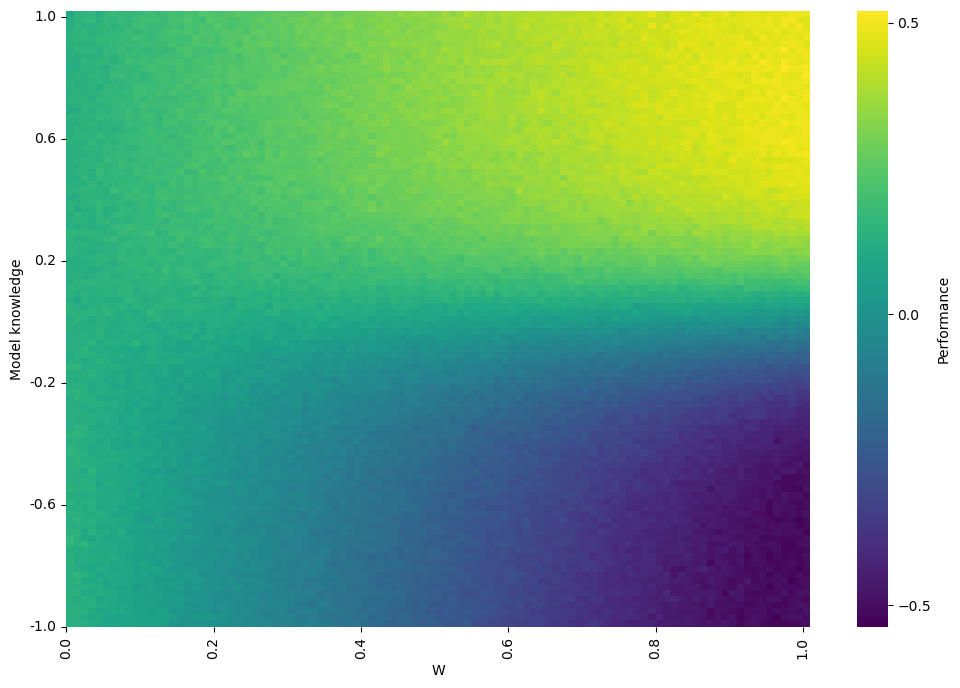

In [19]:
plt.figure(figsize=(12, 8))

sns.heatmap(matrix, cmap="viridis", annot=False, cbar_kws={"label": "Performance", "ticks": [-0.5, 0.0, 0.5]})

# plt.contour(matrix.values, levels=[0], colors="black", linewidths=1)
# plt.axhline(y=50, color="red", linestyle="--", linewidth=2)

plt.gca().invert_yaxis()
plt.ylabel("Model knowledge")
plt.xlabel("W")

# Use the actual index and columns
plt.yticks(
    np.arange(0, len(matrix.index), 20),   # positions
    matrix.index[::20]                     # labels
)
plt.xticks(
    np.arange(0, len(matrix.columns), 20),  # positions
    matrix.columns[::20]                    # labels
)

plt.show()
